# CaseGraph - Feature 9: time to disposal (XGBoost)

Predict how many days a case will take from filing to disposal, with an 80% confidence range.

What this notebook does, top to bottom:

1. Pull disposed cases from Neo4j
2. Clean them and look at the target
3. Build features that are known at filing time (no leakage)
4. Train three XGBoost models: median, 10th percentile, 90th percentile
5. Evaluate against a naive baseline
6. Save the model where the API expects it, then predict a pending case

Run every cell in order (Run > Run All Cells). Set `ROWS` smaller for a quick run.

In [1]:
import os, sys, json, time
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
print("working dir:", root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score

from app.ml.pendency.data import fetch_training_frame, fetch_case
from app.ml.pendency.features import build_matrix, clean_training_frame, fit_encoders, log_target, unlog
from app.ml.pendency.predict import PendencyModel

ROWS = int(os.environ.get("PENDENCY_ROWS", 200_000))
ROUNDS = int(os.environ.get("PENDENCY_ROUNDS", 3000))
DEVICE = os.environ.get("PENDENCY_DEVICE", "cuda")
OUT = Path("models/pendency")
GOLD, INK, MUTED = "#c99a12", "#1d1d1d", "#8f887b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
print(f"ROWS={ROWS} ROUNDS={ROUNDS} DEVICE={DEVICE} xgboost={xgb.__version__}")

working dir: D:\judiciary-copilot\backend
ROWS=200000 ROUNDS=3000 DEVICE=cuda xgboost=3.4.1


## 1. Pull disposed cases from the graph

In [2]:
t = time.time()
raw = fetch_training_frame(ROWS)
print(f"{len(raw):,} disposed cases pulled in {time.time()-t:.1f}s")
raw.head()

200,000 disposed cases pulled in 17.5s


,cnr,filing_date,decision_date,first_hearing,criminal,state,district,court,case_type,pet_adv_present,def_adv_present,pet_state_party,def_state_party,bailable_ipc,number_sections_ipc,judge_position,sections
0,MHST030034342015,2015-12-08,2017-02-11,2015-12-15,True,Maharashtra,Satara,1-31-24,r.c.c.,True,True,True,False,False,2.0,chief judicial magistrate,[IPC-379]
1,MHST030003512015,2015-01-30,2015-10-08,2015-02-02,False,Maharashtra,Satara,1-31-15,criminal appeal,True,False,False,False,None,NaN,chief judicial magistrate,[]
2,MHST030031072015,2015-10-30,2017-08-24,2015-11-21,True,Maharashtra,Satara,1-31-23,r.c.c.,True,True,True,False,True,6.0,chief judicial magistrate,[IPC-506]
3,MHST030006052015,2015-02-25,2017-07-24,2015-03-24,True,Maharashtra,Satara,1-31-23,r.c.c.,True,True,True,False,True,5.0,chief judicial magistrate,[IPC-325]
4,MHST030001372015,2015-01-09,2015-01-09,2015-01-09,True,Maharashtra,Satara,1-31-23,s.c.c.,True,False,True,False,True,1.0,chief judicial magistrate,[IPC-283]


## 2. Clean and look at the target

The target is `days` = decision date minus filing date. We drop negative values (bad data) and anything above 6000 days.

In [3]:
df = clean_training_frame(raw)
print(f"kept {len(df):,} of {len(raw):,}")
df["days"].describe().round(0)

kept 199,840 of 200,000


count    199840.0
mean        460.0
std         537.0
min           0.0
25%          26.0
50%         259.0
75%         716.0
max        3633.0
Name: days, dtype: float64

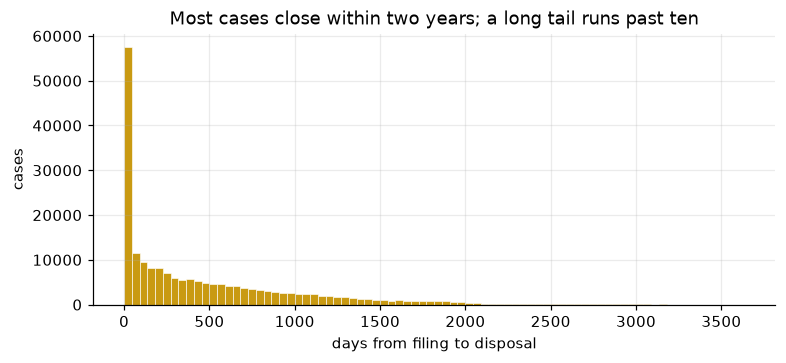

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["days"], bins=80, color=GOLD, edgecolor="white", linewidth=0.4)
ax.set_xlabel("days from filing to disposal"); ax.set_ylabel("cases")
ax.set_title("Most cases close within two years; a long tail runs past ten")
plt.show()

Which states and case types take longest? This is the intuition the model has to learn.

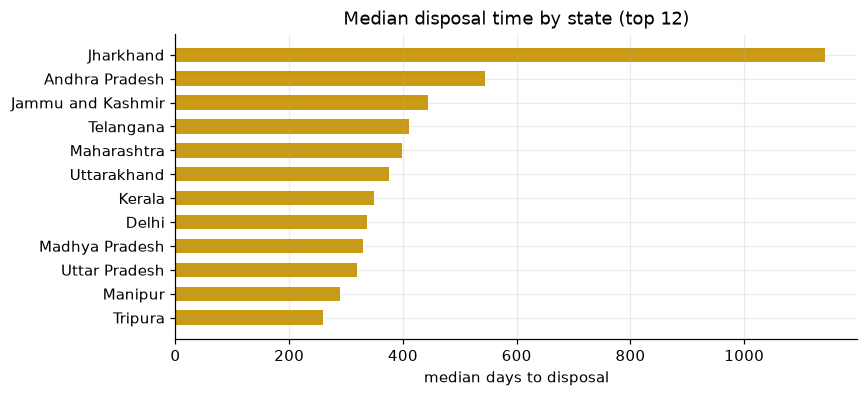

,n,median_days
case_type,,
g.r. case,465,1851.0
maintenance case,416,1410.5
cc,2474,1363.0
l.a.o.p,418,1176.0
exe r,325,1175.0
title suit divorse,671,1082.0
complaint,254,1077.0
session trial,671,1038.0
pauper suit,745,1035.0


In [5]:
by_state = df.groupby("state")["days"].median().sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(by_state.index[::-1], by_state.values[::-1], color=GOLD, height=0.6)
ax.set_xlabel("median days to disposal"); ax.set_title("Median disposal time by state (top 12)")
plt.show()

df.groupby("case_type")["days"].agg(n="size", median_days="median").query("n >= 200").sort_values("median_days", ascending=False).head(10)

## 3. Features known at filing time

Anything that only becomes known later (current stage, disposition, last or next hearing) is excluded on purpose. Using it would make the model look great in a notebook and useless in production.

- Categorical: state, district, court, case type, judge position (XGBoost handles these natively)
- Numeric: filing year, month, weekday, gap to first hearing, criminal flag, number of sections, IPC and CrPC flags, advocate present on each side, whether the state or a public body is a party, bailable IPC flag, number of IPC sections
- Indicators for the 40 most common sections

In [6]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
enc = fit_encoders(train_df, top_k_sections=40)
X_train, X_test = build_matrix(train_df, enc), build_matrix(test_df, enc)
y_train, y_test = log_target(train_df["days"]), log_target(test_df["days"])
print(f"train {X_train.shape}  test {X_test.shape}")
print("top sections:", enc.top_sections[:10])
X_train.head()

train (159872, 59)  test (39968, 59)
top sections: ['CrPC-438', 'IPC-506', 'CrPC-125', 'IPC-279', 'IPC-379', 'CrPC-457', 'IPC-307', 'IPC-338', 'IPC-304', 'IPC-324']


,filing_year,filing_month,filing_dow,first_hearing_gap_days,criminal,n_sections,has_ipc,has_crpc,pet_adv_present,def_adv_present,...,sec_IPC-306,sec_CrPC-156,sec_IPC-467,sec_IPC-406,sec_IPC-395,sec_IPC-376,sec_IPC-337,sec_CrPC-446,sec_IPC-125,sec_CrPC-128
193932,2013.0,6.0,0.0,32.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
110208,2013.0,11.0,4.0,19.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29890,2013.0,12.0,1.0,51.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
190100,2015.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
80587,2013.0,5.0,1.0,11.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Train

We predict `log(1 + days)` because the target is heavy-tailed. Three boosters:

- `median`: squared error on the log target
- `low`: quantile regression at alpha 0.08
- `high`: quantile regression at alpha 0.92 (slightly wider than 0.1/0.9 because the first run covered only 76%)

Early stopping on a 10% validation slice picks the number of trees.

In [7]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42)
dfit = xgb.DMatrix(X_fit, label=y_fit, enable_categorical=True)
dval = xgb.DMatrix(X_val, label=y_val, enable_categorical=True)
dtest = xgb.DMatrix(X_test, enable_categorical=True)

params = dict(tree_method="hist", device=DEVICE, max_depth=8, learning_rate=0.05, subsample=0.85,
              colsample_bytree=0.8, min_child_weight=5, reg_lambda=2.0, max_cat_to_onehot=1, max_bin=256, seed=42)

try:
    xgb.train({**params, "objective": "reg:squarederror"}, dfit, num_boost_round=1)
except xgb.core.XGBoostError as exc:
    print("GPU not usable, using CPU:", str(exc).splitlines()[0]); params["device"] = "cpu"

def fit(objective, **extra):
    return xgb.train({**params, "objective": objective, **extra}, dfit, num_boost_round=ROUNDS,
                     evals=[(dval, "valid")], early_stopping_rounds=100, verbose_eval=200)

t = time.time()
median_model = fit("reg:squarederror")
low_model = fit("reg:quantileerror", quantile_alpha=0.08)
high_model = fit("reg:quantileerror", quantile_alpha=0.92)
print(f"trained in {time.time()-t:.0f}s; best iterations: {median_model.best_iteration}, {low_model.best_iteration}, {high_model.best_iteration}")

D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:09:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:09:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:09:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:09:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:2

[0]	valid-rmse:2.18569
[200]	valid-rmse:0.91548
[400]	valid-rmse:0.90247
[600]	valid-rmse:0.89821
[800]	valid-rmse:0.89681
[887]	valid-rmse:0.89680
[0]	valid-quantile:0.37976


D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:10:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:10:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[200]	valid-quantile:0.14531
[400]	valid-quantile:0.12011
[600]	valid-quantile:0.11743
[800]	valid-quantile:0.11661
[1000]	valid-quantile:0.11618
[1200]	valid-quantile:0.11548
[1400]	valid-quantile:0.11516
[1600]	valid-quantile:0.11497
[1800]	valid-quantile:0.11486
[2000]	valid-quantile:0.11470
[2200]	valid-quantile:0.11451
[2400]	valid-quantile:0.11447
[2487]	valid-quantile:0.11448
[0]	valid-quantile:0.21296


D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:10:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
D:\judiciary-copilot\backend\.venv\Lib\site-packages\xgboost\callback.py:385: UserWarning: [22:10:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[200]	valid-quantile:0.12954
[400]	valid-quantile:0.11461
[600]	valid-quantile:0.10903
[800]	valid-quantile:0.10675
[1000]	valid-quantile:0.10598
[1200]	valid-quantile:0.10570
[1400]	valid-quantile:0.10561
[1600]	valid-quantile:0.10551
[1800]	valid-quantile:0.10548
[1885]	valid-quantile:0.10549
trained in 90s; best iterations: 787, 2387, 1785


## 5. Evaluate

The baseline is "always predict the overall median". A useful model must beat it clearly. Coverage of the 80% range should sit near 80%.

In [8]:
def predict(model, d):
    return unlog(model.predict(d, iteration_range=(0, model.best_iteration + 1)))

y_days = test_df["days"].to_numpy(dtype=float)
pred = predict(median_model, dtest)
low = np.minimum(predict(low_model, dtest), pred)
high = np.maximum(predict(high_model, dtest), pred)

metrics = {
    "mae_days": mean_absolute_error(y_days, pred),
    "median_ae_days": median_absolute_error(y_days, pred),
    "baseline_mae_days_global_median": mean_absolute_error(y_days, np.full_like(y_days, np.median(y_days))),
    "r2_log": r2_score(np.log1p(y_days), np.log1p(pred)),
    "within_90_days_pct": np.mean(np.abs(y_days - pred) <= 90) * 100,
    "within_180_days_pct": np.mean(np.abs(y_days - pred) <= 180) * 100,
    "interval_80_coverage_pct": np.mean((y_days >= low) & (y_days <= high)) * 100,
    "interval_80_mean_width_days": np.mean(high - low),
}
pd.Series(metrics).round(1).to_frame("value")

,value
mae_days,199.8
median_ae_days,88.5
baseline_mae_days_global_median,396.1
r2_log,0.8
within_90_days_pct,50.3
within_180_days_pct,64.8
interval_80_coverage_pct,81.2
interval_80_mean_width_days,616.0


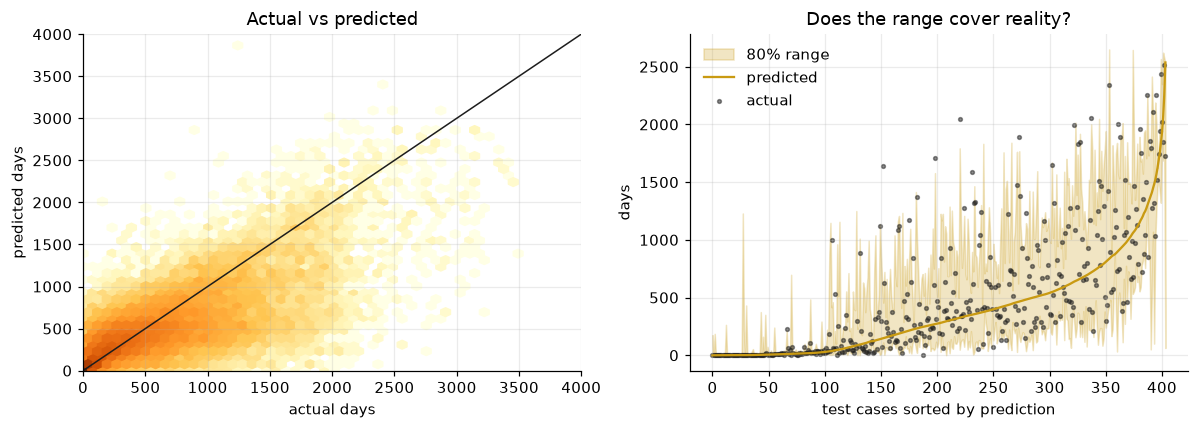

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hexbin(y_days, pred, gridsize=45, cmap="YlOrBr", bins="log", mincnt=1)
lim = [0, 4000]; axes[0].plot(lim, lim, color=INK, linewidth=1)
axes[0].set_xlim(lim); axes[0].set_ylim(lim); axes[0].set_xlabel("actual days"); axes[0].set_ylabel("predicted days"); axes[0].set_title("Actual vs predicted")

order = np.argsort(pred)[:: max(1, len(pred) // 400)]
axes[1].fill_between(range(len(order)), low[order], high[order], color=GOLD, alpha=0.25, label="80% range")
axes[1].plot(pred[order], color=GOLD, linewidth=1.5, label="predicted")
axes[1].scatter(range(len(order)), y_days[order], s=6, color=INK, alpha=0.5, label="actual")
axes[1].set_xlabel("test cases sorted by prediction"); axes[1].set_ylabel("days"); axes[1].set_title("Does the range cover reality?"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. What did the model use?

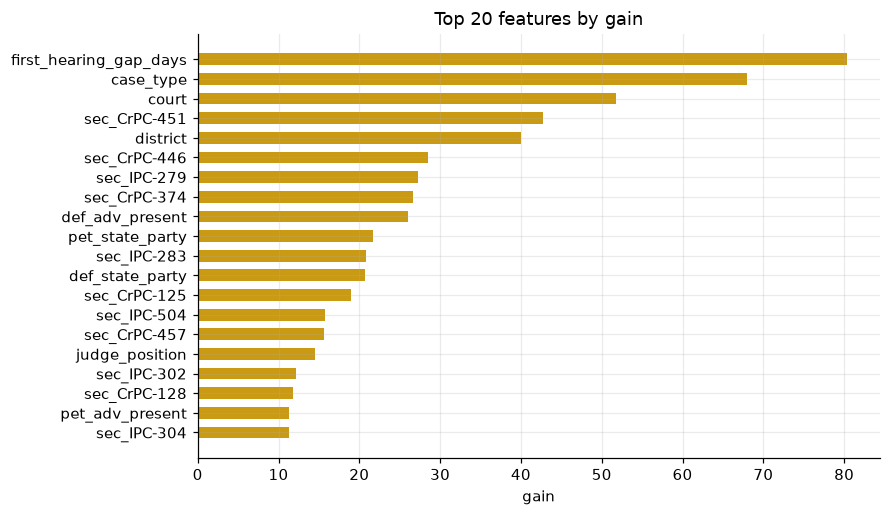

In [10]:
gain = pd.Series(median_model.get_score(importance_type="gain")).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(gain.index[::-1], gain.values[::-1], color=GOLD, height=0.6)
ax.set_xlabel("gain"); ax.set_title("Top 20 features by gain")
plt.show()

## 7. Save for the API

Same files the training script writes, so `GET /predict/disposal/{cnr}` works after the API restarts.

In [11]:
import joblib
from dataclasses import asdict
OUT.mkdir(parents=True, exist_ok=True)
median_model.save_model(OUT / "median.ubj"); low_model.save_model(OUT / "low.ubj"); high_model.save_model(OUT / "high.ubj")
joblib.dump(asdict(enc), OUT / "encoders.joblib")
metrics_out = {k: float(v) for k, v in metrics.items()}
metrics_out.update(n_train=int(len(train_df)), n_test=int(len(test_df)), device=params["device"], trained_at=time.strftime("%Y-%m-%dT%H:%M:%S"), xgboost=xgb.__version__, source="notebook")
(OUT / "metrics.json").write_text(json.dumps(metrics_out, indent=2))
(OUT / "feature_importance.json").write_text(json.dumps(gain.round(2).to_dict(), indent=2))
print("saved to", OUT.resolve()); sorted(p.name for p in OUT.iterdir())

saved to D:\judiciary-copilot\backend\models\pendency


['encoders.joblib',
 'feature_importance.json',
 'high.ubj',
 'low.ubj',
 'median.ubj',
 'metrics.json',
 'metrics_v1.json',
 'test_predictions.csv']

## 8. Predict a pending case

In [12]:
model = PendencyModel(OUT)
case = fetch_case("MHNB030003102010")
result = model.predict_case(case)
print(json.dumps({k: v for k, v in result.items() if k not in ("features",)}, indent=2, default=str))

{
  "cnr": "MHNB030003102010",
  "status": "pending",
  "court": "Chief Judcial Magistrate Nandurbar, Nandurbar",
  "case_type": "cri.m.a.",
  "filing_date": "2010-03-29",
  "predicted_days": 508,
  "predicted_years": 1.39,
  "range_80_days": [
    41,
    1315
  ],
  "range_80_years": [
    0.11,
    3.6
  ],
  "days_elapsed": 6012,
  "benchmark_same_court": {
    "n": 333,
    "median_days": 353,
    "p10_days": 7.0,
    "p90_days": 1653.0
  },
  "model": {
    "trained_at": "2026-09-13T22:11:21",
    "mae_days": 199.84482043374683,
    "interval_80_coverage_pct": 81.15492393915133
  }
}


## Try next

- Increase `ROWS` after loading more cases (`POST /admin/load/ecourts?rows=300000`).
- Change `max_depth`, `learning_rate` or `top_k_sections` and watch `mae_days` and coverage.
- Order 14 in the build plan adds SHAP explanations on top of this exact model.